<a href="https://colab.research.google.com/github/KesteHarshada87/Reinforcement_Learning/blob/main/Expt10(DQN_Agent).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Environment: CartPole-v1
State size: 4
Number of actions: 2
DQN Episode 50/600, Average Reward: 25.70, Epsilon: 0.778
DQN Episode 100/600, Average Reward: 37.70, Epsilon: 0.606
DQN Episode 150/600, Average Reward: 55.14, Epsilon: 0.471
DQN Episode 200/600, Average Reward: 52.72, Epsilon: 0.367
DQN Episode 250/600, Average Reward: 57.64, Epsilon: 0.286
DQN Episode 300/600, Average Reward: 77.50, Epsilon: 0.222
DQN Episode 350/600, Average Reward: 123.40, Epsilon: 0.173
DQN Episode 400/600, Average Reward: 122.16, Epsilon: 0.135
DQN Episode 450/600, Average Reward: 100.92, Epsilon: 0.105
DQN Episode 500/600, Average Reward: 81.00, Epsilon: 0.082
DQN Episode 550/600, Average Reward: 87.14, Epsilon: 0.063
DQN Episode 600/600, Average Reward: 162.00, Epsilon: 0.049
Tabular Episode 50/600, Average Reward: 24.86, Epsilon: 0.778
Tabular Episode 100/600, Average Reward: 29.48, Epsilon: 0.606
Tabular Episode 150/600, Average Reward: 25.76, Epsilon: 0.471
Tabular Episode 200/600, Average Reward: 

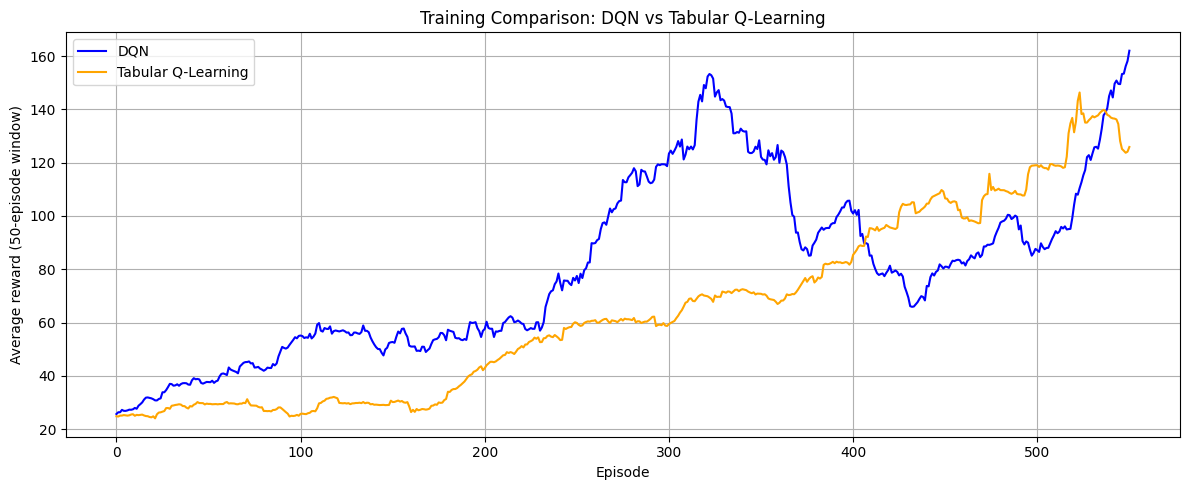

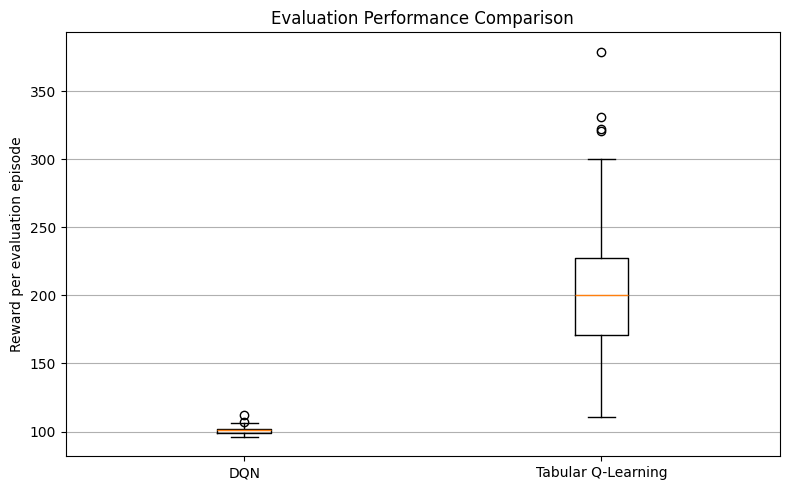


Experiment 10 completed successfully.


In [1]:
import random
from collections import deque

import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim

# =========================================================
# EXPERIMENT 10: DQN vs TABULAR Q-LEARNING ON CARTPOLE
# =========================================================

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

ENV_NAME = "CartPole-v1"
env = gym.make(ENV_NAME)

state_size = env.observation_space.shape[0]  # 4
action_size = env.action_space.n             # 2

print("Environment:", ENV_NAME)
print("State size:", state_size)
print("Number of actions:", action_size)

# Common training settings
EPISODES = 600
MAX_STEPS = 500
GAMMA = 0.99
EVAL_EPISODES = 100


# =========================================================
# PART A: DEEP Q-NETWORK (DQN)
# =========================================================

class DQN(nn.Module):
    def __init__(self, state_size, action_size):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(state_size, 128),
            nn.ReLU(),
            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Linear(128, action_size)
        )

    def forward(self, state):
        return self.network(state)


class DQNAgent:
    def __init__(self):
        self.device = torch.device(
            "cuda" if torch.cuda.is_available() else "cpu"
        )

        self.policy_net = DQN(
            state_size, action_size
        ).to(self.device)

        self.target_net = DQN(
            state_size, action_size
        ).to(self.device)

        self.target_net.load_state_dict(
            self.policy_net.state_dict()
        )
        self.target_net.eval()

        self.optimizer = optim.Adam(
            self.policy_net.parameters(), lr=0.001
        )

        self.memory = deque(maxlen=20000)
        self.batch_size = 64
        self.gamma = GAMMA
        self.epsilon = 1.0
        self.epsilon_min = 0.02
        self.epsilon_decay = 0.995
        self.target_update = 500
        self.steps = 0

    def choose_action(self, state, training=True):
        if training and random.random() < self.epsilon:
            return random.randrange(action_size)

        state_tensor = torch.as_tensor(
            state, dtype=torch.float32, device=self.device
        ).unsqueeze(0)

        with torch.no_grad():
            q_values = self.policy_net(state_tensor)

        return int(q_values.argmax(dim=1).item())

    def remember(self, state, action, reward,
                 next_state, terminated):
        self.memory.append(
            (state, action, reward, next_state, terminated)
        )

    def train_step(self):
        if len(self.memory) < self.batch_size:
            return

        batch = random.sample(self.memory, self.batch_size)

        states, actions, rewards, next_states, dones = zip(*batch)

        states = torch.as_tensor(
            np.array(states), dtype=torch.float32,
            device=self.device
        )
        actions = torch.as_tensor(
            actions, dtype=torch.long, device=self.device
        ).unsqueeze(1)
        rewards = torch.as_tensor(
            rewards, dtype=torch.float32, device=self.device
        )
        next_states = torch.as_tensor(
            np.array(next_states), dtype=torch.float32,
            device=self.device
        )
        dones = torch.as_tensor(
            dones, dtype=torch.float32, device=self.device
        )

        # Q(s, a) predicted by the policy network
        current_q = self.policy_net(states).gather(
            1, actions
        ).squeeze(1)

        # Target: r + gamma * max Q_target(s', a')
        with torch.no_grad():
            next_q = self.target_net(next_states).max(
                dim=1
            )[0]

            target_q = rewards + self.gamma * (
                1 - dones
            ) * next_q

        loss = nn.functional.smooth_l1_loss(
            current_q, target_q
        )

        self.optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(
            self.policy_net.parameters(), 10.0
        )
        self.optimizer.step()

        self.steps += 1

        # Periodically synchronize the target network
        if self.steps % self.target_update == 0:
            self.target_net.load_state_dict(
                self.policy_net.state_dict()
            )

    def decay_epsilon(self):
        self.epsilon = max(
            self.epsilon_min,
            self.epsilon * self.epsilon_decay
        )


# Train DQN
dqn_env = gym.make(ENV_NAME)
dqn_agent = DQNAgent()
dqn_rewards = []

for episode in range(EPISODES):
    state, info = dqn_env.reset(seed=SEED + episode)
    total_reward = 0

    for step in range(MAX_STEPS):
        action = dqn_agent.choose_action(state)

        next_state, reward, terminated, truncated, info = (
            dqn_env.step(action)
        )

        # Store termination separately from time-limit truncation.
        # A time-limit truncation still permits bootstrapping.
        dqn_agent.remember(
            state, action, reward, next_state, terminated
        )
        dqn_agent.train_step()

        state = next_state
        total_reward += reward

        if terminated or truncated:
            break

    dqn_agent.decay_epsilon()
    dqn_rewards.append(total_reward)

    if (episode + 1) % 50 == 0:
        recent = np.mean(dqn_rewards[-50:])
        print(
            f"DQN Episode {episode + 1}/{EPISODES}, "
            f"Average Reward: {recent:.2f}, "
            f"Epsilon: {dqn_agent.epsilon:.3f}"
        )

dqn_env.close()


# =========================================================
# PART B: TABULAR Q-LEARNING
# =========================================================

# Discretize the four continuous CartPole observations.
# Clip extreme values to keep the table finite.
bins = [
    np.linspace(-4.8, 4.8, 10),
    np.linspace(-3.0, 3.0, 10),
    np.linspace(-0.418, 0.418, 10),
    np.linspace(-3.5, 3.5, 10)
]

table_shape = tuple(len(b) + 1 for b in bins) + (action_size,)
Q_table = np.zeros(table_shape)


def discretize(state):
    clipped = np.clip(
        state,
        [-4.8, -3.0, -0.418, -3.5],
        [4.8, 3.0, 0.418, 3.5]
    )

    return tuple(
        int(np.digitize(clipped[i], bins[i]))
        for i in range(state_size)
    )


# Tabular Q-Learning parameters
alpha = 0.1
epsilon = 1.0
epsilon_min = 0.02
epsilon_decay = 0.995

tabular_env = gym.make(ENV_NAME)
tabular_rewards = []

for episode in range(EPISODES):
    state, info = tabular_env.reset(seed=SEED + episode)
    state_idx = discretize(state)
    total_reward = 0

    for step in range(MAX_STEPS):
        # Epsilon-greedy action selection
        if random.random() < epsilon:
            action = tabular_env.action_space.sample()
        else:
            action = int(np.argmax(Q_table[state_idx]))

        next_state, reward, terminated, truncated, info = (
            tabular_env.step(action)
        )

        next_idx = discretize(next_state)
        done = terminated or truncated

        # Do not bootstrap beyond a true terminal state.
        # Truncation is a time limit, so bootstrap from next state.
        if terminated:
            target = reward
        else:
            target = reward + GAMMA * np.max(
                Q_table[next_idx]
            )

        Q_table[state_idx + (action,)] += alpha * (
            target - Q_table[state_idx + (action,)]
        )

        state_idx = next_idx
        total_reward += reward

        if done:
            break

    epsilon = max(epsilon_min, epsilon * epsilon_decay)
    tabular_rewards.append(total_reward)

    if (episode + 1) % 50 == 0:
        recent = np.mean(tabular_rewards[-50:])
        print(
            f"Tabular Episode {episode + 1}/{EPISODES}, "
            f"Average Reward: {recent:.2f}, "
            f"Epsilon: {epsilon:.3f}"
        )

tabular_env.close()


# =========================================================
# PART C: EVALUATE BOTH LEARNED POLICIES
# =========================================================

def evaluate_dqn(agent, episodes=EVAL_EPISODES):
    test_env = gym.make(ENV_NAME)
    rewards = []

    for ep in range(episodes):
        state, info = test_env.reset(seed=10000 + ep)
        total_reward = 0

        for step in range(MAX_STEPS):
            action = agent.choose_action(state, training=False)

            state, reward, terminated, truncated, info = (
                test_env.step(action)
            )
            total_reward += reward

            if terminated or truncated:
                break

        rewards.append(total_reward)

    test_env.close()
    return np.array(rewards)


def evaluate_tabular(Q, episodes=EVAL_EPISODES):
    test_env = gym.make(ENV_NAME)
    rewards = []

    for ep in range(episodes):
        state, info = test_env.reset(seed=10000 + ep)
        total_reward = 0

        for step in range(MAX_STEPS):
            state_idx = discretize(state)
            action = int(np.argmax(Q[state_idx]))

            state, reward, terminated, truncated, info = (
                test_env.step(action)
            )
            total_reward += reward

            if terminated or truncated:
                break

        rewards.append(total_reward)

    test_env.close()
    return np.array(rewards)


dqn_test = evaluate_dqn(dqn_agent)
tabular_test = evaluate_tabular(Q_table)

print("\n========== FINAL EVALUATION ==========")
print(f"Evaluation episodes: {EVAL_EPISODES}")
print(f"DQN average reward: {np.mean(dqn_test):.2f}")
print(f"DQN standard deviation: {np.std(dqn_test):.2f}")
print(f"Tabular Q-Learning average reward: {np.mean(tabular_test):.2f}")
print(f"Tabular Q-Learning standard deviation: {np.std(tabular_test):.2f}")

# CartPole is conventionally considered solved when the
# average return reaches at least 475 over 100 episodes.
print(
    "DQN solved (average >= 475):",
    np.mean(dqn_test) >= 475
)
print(
    "Tabular Q-Learning solved (average >= 475):",
    np.mean(tabular_test) >= 475
)


# =========================================================
# PART D: PLOT TRAINING AND EVALUATION RESULTS
# =========================================================

def moving_average(data, window=50):
    return np.convolve(
        data,
        np.ones(window) / window,
        mode="valid"
    )


plt.figure(figsize=(12, 5))
plt.plot(
    moving_average(dqn_rewards),
    label="DQN",
    color="blue"
)
plt.plot(
    moving_average(tabular_rewards),
    label="Tabular Q-Learning",
    color="orange"
)
plt.xlabel("Episode")
plt.ylabel("Average reward (50-episode window)")
plt.title("Training Comparison: DQN vs Tabular Q-Learning")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


plt.figure(figsize=(8, 5))
plt.boxplot(
    [dqn_test, tabular_test],
    tick_labels=["DQN", "Tabular Q-Learning"]
)
plt.ylabel("Reward per evaluation episode")
plt.title("Evaluation Performance Comparison")
plt.grid(axis="y")
plt.tight_layout()
plt.show()

print("\nExperiment 10 completed successfully.")